In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/metadata.csv
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_492_937_958.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_13_21_350.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_456_887_499.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_15_1001_749.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_456_888_961.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_158_621_68.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_48_74_309.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_88_133_64.png
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1/PAT_460_893_307.png
/kaggle/input/data

In [2]:
import os
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

In [3]:
import os

folders = [
"/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1",
"/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_2/imgs_part_2",
"/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_3/imgs_part_3"
]

total_images = 0

for folder in folders:
    count = 0
    for file in os.listdir(folder):
        if file.endswith(".png") or file.endswith(".jpg") or file.endswith(".jpeg"):
            count += 1
    print(f"{folder} → {count} images")
    total_images += count

print("\nTotal images in all folders:", total_images)

/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1 → 911 images
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_2/imgs_part_2 → 659 images
/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_3/imgs_part_3 → 728 images

Total images in all folders: 2298


In [4]:
import os

dataset_path = "/kaggle/input/datasets/niharkumardash/skin-cancer-dataset"

print(os.path.exists(dataset_path))

True


In [5]:
for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("-----")

Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset
Number of files: 1
-----
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1
Number of files: 0
-----
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1
Number of files: 911
-----
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_3
Number of files: 0
-----
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_3/imgs_part_3
Number of files: 728
-----
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_2
Number of files: 0
-----
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_2/imgs_part_2
Number of files: 659
-----


In [6]:
import cv2
import os
import numpy as np

dataset_path = "/kaggle/input/datasets/niharkumardash/skin-cancer-dataset"

images = []
image_ids = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".png"):
            
            path = os.path.join(root, file)

            img = cv2.imread(path)

            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                
                img = cv2.resize(img,(224,224))
                img = img / 255.0
                
                images.append(img)
                
                image_ids.append(file.replace(".png",""))

images = np.array(images)

print("Shape of dataset:", images.shape)
print("Total image IDs:", len(image_ids))

print("\nFirst 10 Image IDs:")
for i in range(10):
    print(image_ids[i])

Shape of dataset: (2298, 224, 224, 3)
Total image IDs: 2298

First 10 Image IDs:
PAT_492_937_958
PAT_13_21_350
PAT_456_887_499
PAT_15_1001_749
PAT_456_888_961
PAT_158_621_68
PAT_48_74_309
PAT_88_133_64
PAT_460_893_307
PAT_386_1554_455


In [7]:
index = image_ids.index("PAT_492_937_958")
print(index)

0


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

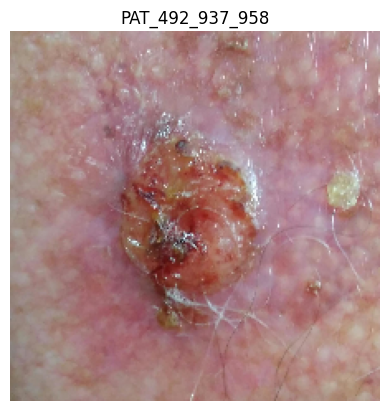

In [8]:
plt.imshow(images[0])
plt.title("PAT_492_937_958")
plt.axis("off")

In [9]:


print(image_ids[:5])

['PAT_492_937_958', 'PAT_13_21_350', 'PAT_456_887_499', 'PAT_15_1001_749', 'PAT_456_888_961']


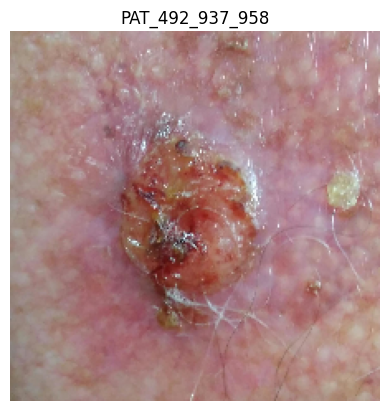

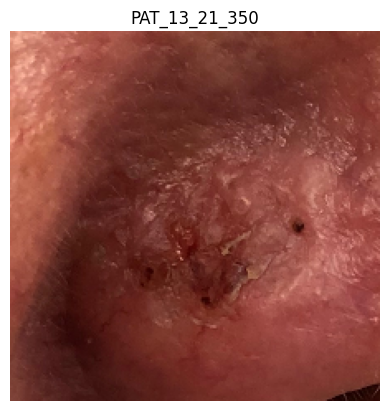

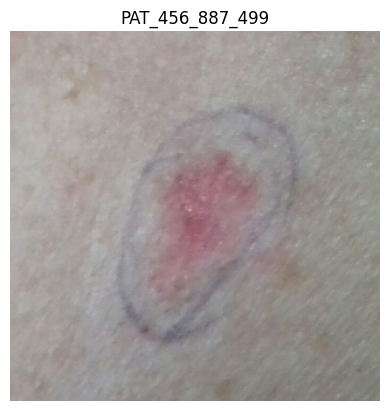

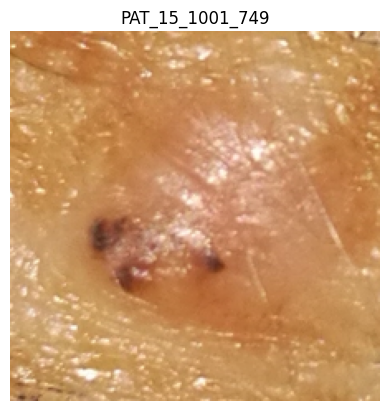

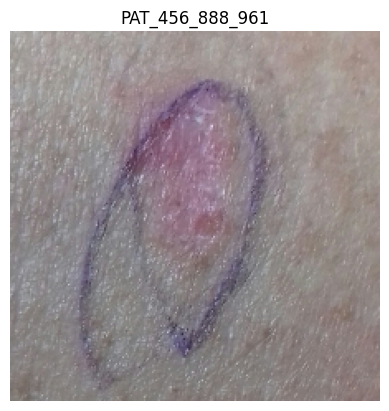

In [10]:
import matplotlib.pyplot as plt

for i in range(5):
    plt.figure()
    plt.imshow(images[i])
    plt.title(image_ids[i])
    plt.axis("off")

Dataset shape: (2298, 224, 224, 3)
Min pixel value: 0.0
Max pixel value: 1.0
First image shape: (224, 224, 3)
Images with wrong shape: 0


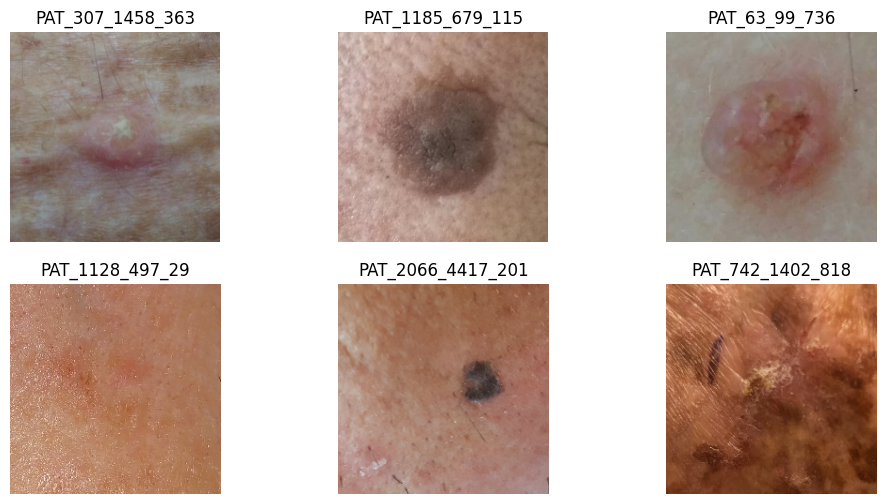

In [11]:
import matplotlib.pyplot as plt
import random
import numpy as np

# 1️⃣ Dataset shape
print("Dataset shape:", images.shape)

# 2️⃣ Pixel value range
print("Min pixel value:", images.min())
print("Max pixel value:", images.max())

# 3️⃣ Image dimension check
print("First image shape:", images[0].shape)

# Check if any image has wrong dimensions
wrong_shapes = [img.shape for img in images if img.shape != (224,224,3)]
print("Images with wrong shape:", len(wrong_shapes))

# 4️⃣ Random image visualization
plt.figure(figsize=(12,6))

for i in range(6):
    idx = random.randint(0, len(images)-1)
    plt.subplot(2,3,i+1)
    plt.imshow(images[idx])
    plt.title(image_ids[idx])
    plt.axis("off")

plt.show()

In [12]:
import numpy as np

bad_images = []

for i, img in enumerate(images):

    # 1️ Check dimension
    if img.shape != (224,224,3):
        bad_images.append((i, "Wrong shape"))

    # 2️ Check NaN values
    if np.isnan(img).any():
        bad_images.append((i, "NaN values"))

    # 3️ Check very dark images
    if img.mean() < 0.05:
        bad_images.append((i, "Too dark"))

    # 4️ Check very bright images
    if img.mean() > 0.95:
        bad_images.append((i, "Too bright"))

    # 5️ Check very low variance (almost blank image)
    if img.std() < 0.01:
        bad_images.append((i, "Low variance"))

print("Total suspicious images:", len(bad_images))

print("Examples:", bad_images[:10])

Total suspicious images: 0
Examples: []


In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

bad_position_images = []

for i, img in enumerate(images):

    # Convert to grayscale
    gray = cv2.cvtColor((img*255).astype("uint8"), cv2.COLOR_BGR2GRAY)

    # Blur to reduce noise
    gray = cv2.GaussianBlur(gray,(5,5),0)

    # Threshold to separate lesion from skin
    _, thresh = cv2.threshold(gray, 50, 255, cv2.THRESH_BINARY_INV)

    # Find contours
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        largest = max(contours, key=cv2.contourArea)
        M = cv2.moments(largest)

        if M["m00"] != 0:
            cx = int(M["m10"]/M["m00"])
            cy = int(M["m01"]/M["m00"])

            # Image center
            center_x, center_y = 112, 112

            # Distance from center
            distance = np.sqrt((cx-center_x)**2 + (cy-center_y)**2)

            if distance > 50:  # threshold
                bad_position_images.append(i)

print("Images with poorly placed lesions:", len(bad_position_images))

Images with poorly placed lesions: 502


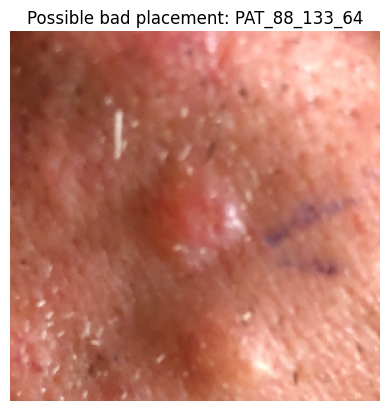

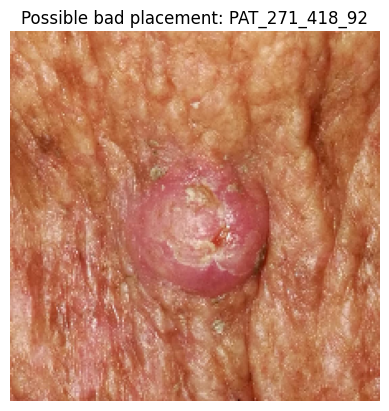

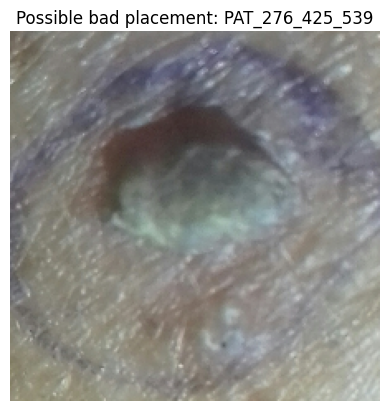

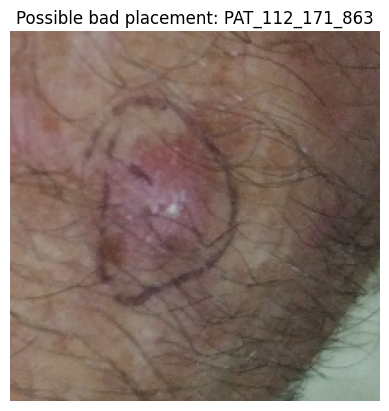

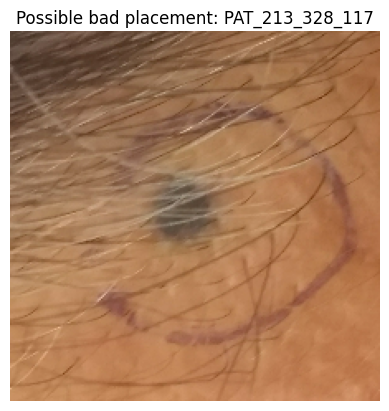

In [14]:
for idx in bad_position_images[:5]:
    plt.figure()
    plt.imshow(images[idx])
    plt.title(f"Possible bad placement: {image_ids[idx]}")
    plt.axis("off")

In [15]:
import cv2
import os

dataset_path = "/kaggle/input/datasets/niharkumardash/skin-cancer-dataset"

bad_ids = [
"PAT_88_133_64",
"PAT_271_418_92",
"PAT_276_425_539",
"PAT_112_171_863",
"PAT_213_328_117"
]

for bad_id in bad_ids:
    
    for root, dirs, files in os.walk(dataset_path):
        for file in files:
            
            if file.startswith(bad_id) and file.endswith(".png"):
                
                path = os.path.join(root, file)
                
                img = cv2.imread(path)

                # Convert BGR → RGB
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                img = cv2.resize(img,(224,224))
                img = img / 255.0
                
                idx = image_ids.index(bad_id)
                images[idx] = img
                
                print(f"{bad_id} restored")

PAT_88_133_64 restored
PAT_271_418_92 restored
PAT_276_425_539 restored
PAT_112_171_863 restored
PAT_213_328_117 restored


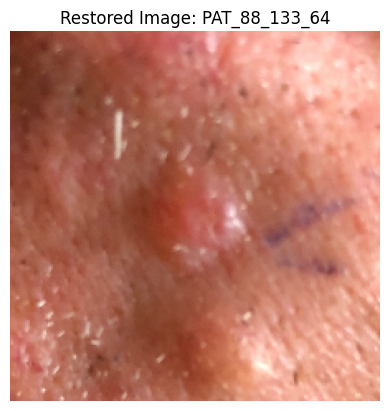

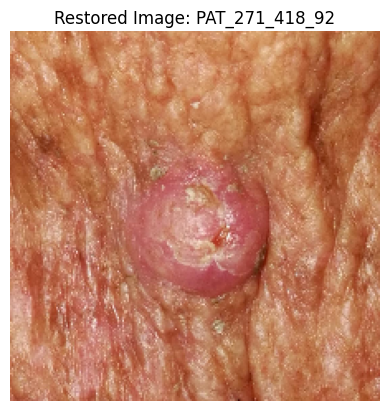

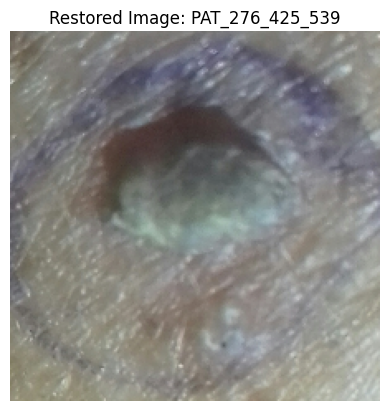

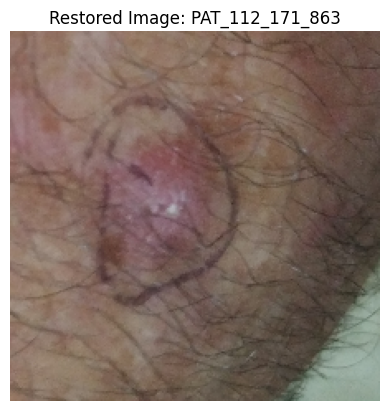

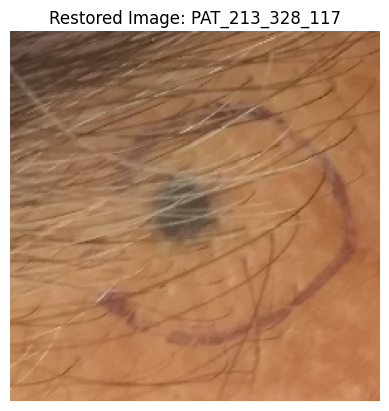

In [16]:
import matplotlib.pyplot as plt

for bad_id in bad_ids:
    
    idx = image_ids.index(bad_id)
    
    plt.figure()
    plt.imshow(images[idx])
    plt.title(f"Restored Image: {bad_id}")
    plt.axis("off")

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

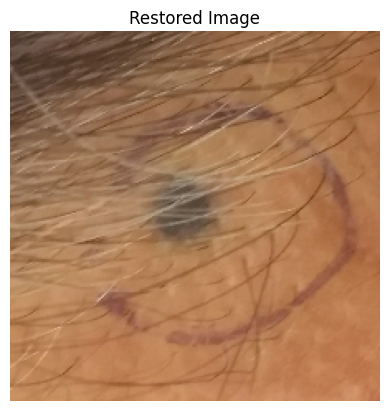

In [17]:
import matplotlib.pyplot as plt

plt.imshow(images[idx])
plt.title("Restored Image")
plt.axis("off")

# Final Dataset Verification Code

Total images: 2298
Dataset shape: (2298, 224, 224, 3)
Shape of first image: (224, 224, 3)
Min pixel value: 0.0
Max pixel value: 1.0
Total image IDs: 2298
Dataset verified: images and IDs match


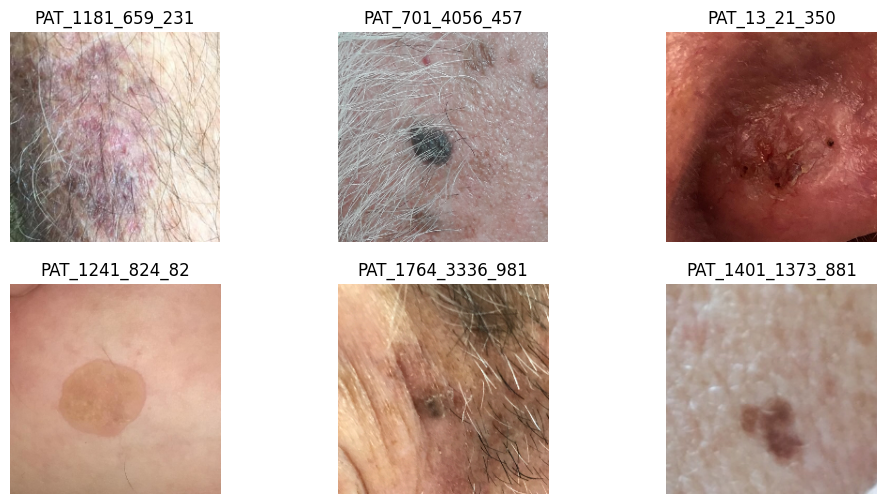

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import random

# 1️ Total images
print("Total images:", len(images))

# 2️ Dataset shape
print("Dataset shape:", images.shape)

# 3️ Check image dimensions
print("Shape of first image:", images[0].shape)

# 4️ Pixel value range
print("Min pixel value:", np.min(images))
print("Max pixel value:", np.max(images))

# 5️ Check ID consistency
print("Total image IDs:", len(image_ids))

if len(images) == len(image_ids):
    print("Dataset verified: images and IDs match")
else:
    print("Mismatch between images and IDs")

# 6️ Random visualization check
plt.figure(figsize=(12,6))

for i in range(6):
    idx = random.randint(0, len(images)-1)

    plt.subplot(2,3,i+1)
    plt.imshow(images[idx])
    plt.title(image_ids[idx])
    plt.axis("off")

plt.show()

In [19]:
import numpy as np

wrong_shape_images = []

for i, img in enumerate(images):
    if img.shape != (224, 224, 3):
        wrong_shape_images.append((i, img.shape))

print("Total images:", len(images))
print("Images with wrong shape:", len(wrong_shape_images))

if len(wrong_shape_images) > 0:
    print("Examples of wrong shapes:", wrong_shape_images[:10])
else:
    print("All images have correct shape (224,224,3)")

Total images: 2298
Images with wrong shape: 0
All images have correct shape (224,224,3)


**MODELLING**

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import cv2
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, Adagrad
from tensorflow.keras.preprocessing.image import ImageDataGenerator

2026-04-06 23:38:43.363851: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775518723.579172      17 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775518723.643174      17 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775518724.169056      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775518724.169101      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775518724.169105      17 computation_placer.cc:177] computation placer alr

In [21]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.19.0
GPU Available: []


2026-04-06 23:39:11.731841: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


**DATA STRUCTURE**

In [22]:
import os

dataset_path = "/kaggle/input"

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))
    print("-"*50)

Folder: /kaggle/input
Subfolders: ['datasets']
Number of files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets
Subfolders: ['niharkumardash']
Number of files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets/niharkumardash
Subfolders: ['skin-cancer-dataset']
Number of files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset
Subfolders: ['imgs_part_1', 'imgs_part_3', 'imgs_part_2']
Number of files: 1
--------------------------------------------------
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1
Subfolders: ['imgs_part_1']
Number of files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1
Subfolders: []
Number of files: 911
--------------------------------------------------
Folder: /kaggle/input/datasets/niharkumardash/skin-c

In [23]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/niharkumardash/skin-cancer-dataset"):
    for file in files:
        if file.endswith(".csv"):
            print("CSV File Found:", os.path.join(root,file))

CSV File Found: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/metadata.csv


In [24]:
import pandas as pd

metadata_path = "/kaggle/input/datasets/niharkumardash/skin-cancer-dataset/metadata.csv"

df = pd.read_csv(metadata_path)

print("Shape of metadata:", df.shape)

df.head()

Shape of metadata: (2298, 26)


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True


In [25]:
print(df.columns)

Index(['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father',
       'background_mother', 'age', 'pesticide', 'gender',
       'skin_cancer_history', 'cancer_history', 'has_piped_water',
       'has_sewage_system', 'fitspatrick', 'region', 'diameter_1',
       'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed',
       'elevation', 'img_id', 'biopsed'],
      dtype='object')


In [26]:
print(df['diagnostic'].unique())

['NEV' 'BCC' 'ACK' 'SEK' 'SCC' 'MEL']


In [27]:
print(df['diagnostic'].value_counts())

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64


In [28]:
df['img_id'].head(2298)

0       PAT_1516_1765_530.png
1          PAT_46_881_939.png
2       PAT_1545_1867_547.png
3       PAT_1989_4061_934.png
4        PAT_684_1302_588.png
                ...          
2293    PAT_1708_3156_175.png
2294       PAT_46_880_140.png
2295    PAT_1343_1217_404.png
2296      PAT_326_690_823.png
2297    PAT_1714_3189_989.png
Name: img_id, Length: 2298, dtype: object

In [29]:
import os

base_path = "/kaggle/input/datasets/niharkumardash/skin-cancer-dataset"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith((".png", ".jpg", ".jpeg")):
            print("Example image:", file)
            print("Location:", root)
            break

Example image: PAT_492_937_958.png
Location: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_1/imgs_part_1
Example image: PAT_1726_3228_674.png
Location: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_3/imgs_part_3
Example image: PAT_650_3858_329.png
Location: /kaggle/input/datasets/niharkumardash/skin-cancer-dataset/imgs_part_2/imgs_part_2


In [30]:
import os

base_path = "/kaggle/input/datasets/niharkumardash/skin-cancer-dataset"

image_paths = []

for img in df['img_id']:

    found = False

    for folder in [
        "imgs_part_1/imgs_part_1",
        "imgs_part_2/imgs_part_2",
        "imgs_part_3/imgs_part_3"
    ]:

        path = os.path.join(base_path, folder, img)

        if os.path.exists(path):
            image_paths.append(path)
            found = True
            break

    if not found:
        image_paths.append(None)

df['image_path'] = image_paths

In [31]:
df[['img_id','image_path','diagnostic']].head()

,img_id,image_path,diagnostic
0,PAT_1516_1765_530.png,/kaggle/input/datasets/niharkumardash/skin-can...,NEV
1,PAT_46_881_939.png,/kaggle/input/datasets/niharkumardash/skin-can...,BCC
2,PAT_1545_1867_547.png,/kaggle/input/datasets/niharkumardash/skin-can...,ACK
3,PAT_1989_4061_934.png,/kaggle/input/datasets/niharkumardash/skin-can...,ACK
4,PAT_684_1302_588.png,/kaggle/input/datasets/niharkumardash/skin-can...,BCC


In [32]:
df['image_path'].isnull().sum()

np.int64(0)

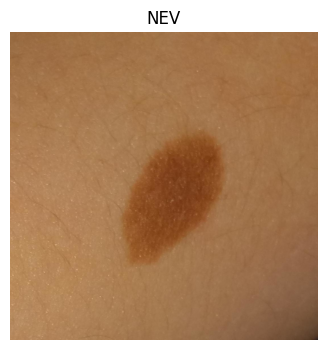

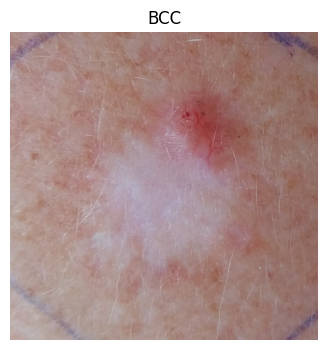

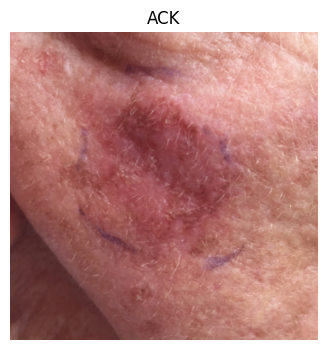

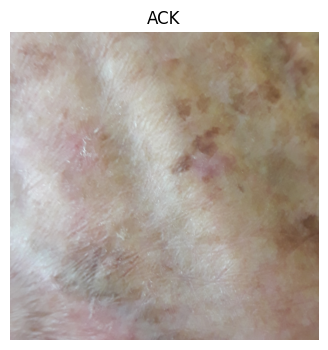

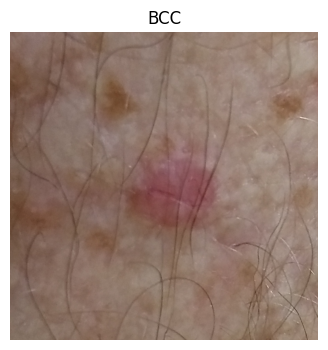

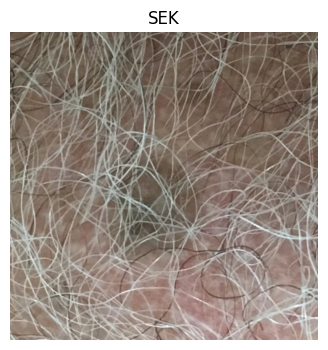

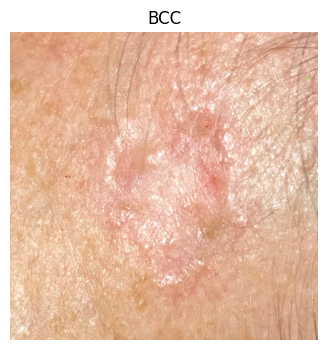

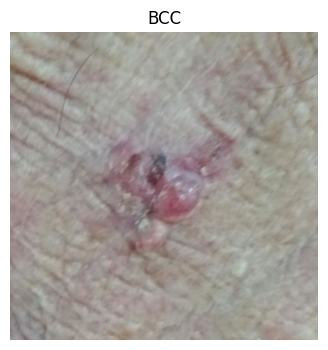

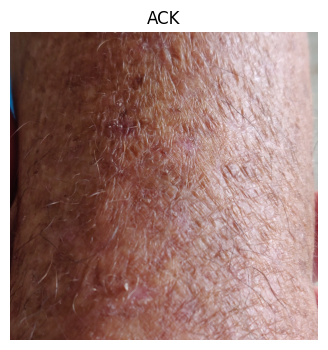

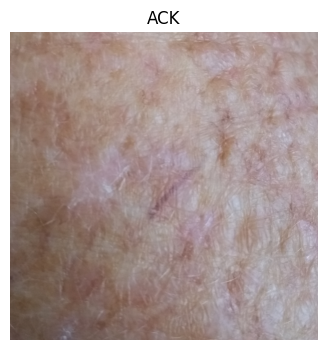

In [33]:
import cv2
import matplotlib.pyplot as plt

# display first 5 images with labels for verification
for i in range(10):
    
    img_path = df.loc[i, 'image_path']
    label = df.loc[i, 'diagnostic']
    
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.title(label)
    plt.axis('off')

In [34]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['label'] = le.fit_transform(df['diagnostic'])

df[['diagnostic','label']].head()

,diagnostic,label
0,NEV,3
1,BCC,1
2,ACK,0
3,ACK,0
4,BCC,1


In [35]:
print(le.classes_)

['ACK' 'BCC' 'MEL' 'NEV' 'SCC' 'SEK']


**TRAIN_TEST_SPLIT**

In [36]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

Training samples: 1838
Validation samples: 460


In [37]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)

In [38]:
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='diagnostic',
    target_size=(240,240),
    batch_size=32,
    class_mode='categorical'
)

Found 1838 validated image filenames belonging to 6 classes.


In [39]:
val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='diagnostic',
    target_size=(240,240),
    batch_size=32,
    class_mode='categorical'
)

Found 460 validated image filenames belonging to 6 classes.


**CNN MODEL BUILDING FROM SCRATCH**

In [40]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential()

# First Convolution Layer
model.add(Conv2D(32, (3,3), activation='relu', input_shape=(240,240,3)))
model.add(MaxPooling2D(2,2))

# Second Convolution Layer
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

# Third Convolution Layer
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

# Flatten
model.add(Flatten())

# Dense Layer
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

# Output Layer (6 classes)
model.add(Dense(6, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [41]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [42]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 238, 238, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 119, 119, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 117, 117, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 58, 58, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,206 (49.36 MB)

 Trainable params: 12,939,206 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

**TRAINING AFTER ADAM OPTIMIZER**

In [43]:
history_adam = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step - accuracy: 0.3399 - loss: 1.8321 - val_accuracy: 0.3674 - val_loss: 1.5212
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 199s 3s/step - accuracy: 0.3841 - loss: 1.5164 - val_accuracy: 0.3696 - val_loss: 1.5159
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 168s 3s/step - accuracy: 0.3610 - loss: 1.5184 - val_accuracy: 0.3674 - val_loss: 1.4909
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 219s 3s/step - accuracy: 0.3881 - loss: 1.5081 - val_accuracy: 0.4543 - val_loss: 1.4382
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.4580 - loss: 1.4138 - val_accuracy: 0.5130 - val_loss: 1.3403
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 184s 3s/step - accuracy: 0.4906 - loss: 1.3647 - val_accuracy: 0.4652 - val_loss: 1.3418
Epoch 7/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 185s 3s/step - accuracy: 0.4861 - loss: 1.3304 - val_accuracy: 0.5043 - val_loss: 1.2699
Epoch 8/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 190s 3s/step - accuracy: 0.5156 - loss: 1.2637 - val_accuracy: 0.5022 - v

**GRAPH FOR CNN**

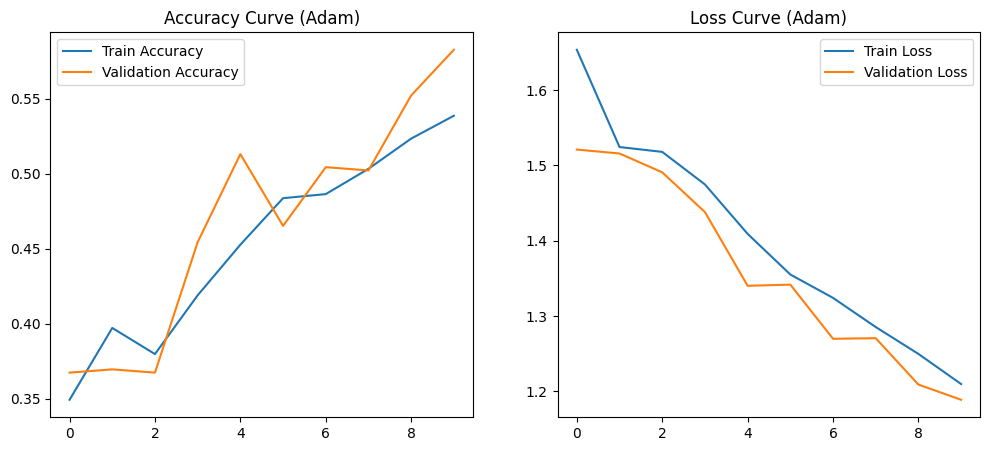

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy plot
plt.subplot(1,2,1)
plt.plot(history_adam.history['accuracy'], label='Train Accuracy')
plt.plot(history_adam.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Curve (Adam)")
plt.legend()

# Loss plot
plt.subplot(1,2,2)
plt.plot(history_adam.history['loss'], label='Train Loss')
plt.plot(history_adam.history['val_loss'], label='Validation Loss')
plt.title("Loss Curve (Adam)")
plt.legend()

plt.show()

**Confusion Matrix for CNN+ADAM**

In [45]:
import numpy as np

val_generator.reset()

predictions = model.predict(val_generator)

predicted_classes = np.argmax(predictions, axis=1)

15/15 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step


In [46]:
true_classes = val_generator.classes #TRUE LABELS

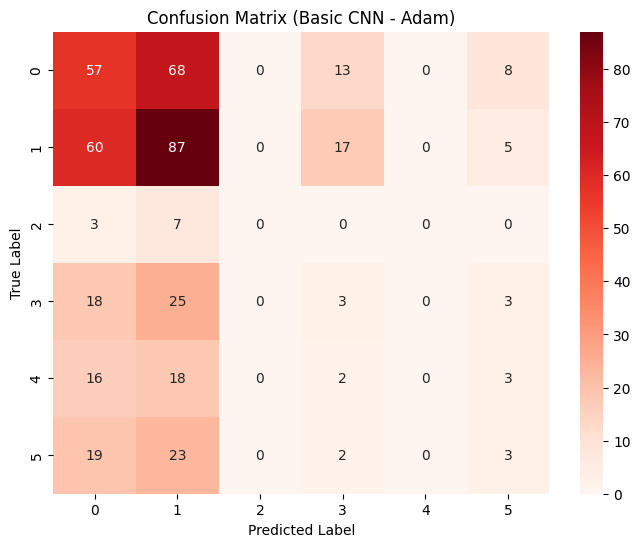

In [47]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Basic CNN - Adam)")

plt.show()

**CNN+RMPSROP OPTIMIZER**

In [48]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model_rms = Sequential()

model_rms.add(Conv2D(32, (3,3), activation='relu', input_shape=(240,240,3)))
model_rms.add(MaxPooling2D(2,2))

model_rms.add(Conv2D(64, (3,3), activation='relu'))
model_rms.add(MaxPooling2D(2,2))

model_rms.add(Conv2D(128, (3,3), activation='relu'))
model_rms.add(MaxPooling2D(2,2))

model_rms.add(Flatten())

model_rms.add(Dense(128, activation='relu'))
model_rms.add(Dropout(0.5))

model_rms.add(Dense(6, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [49]:
#COMPILE WITH RMS PROP OPTIMIZER
from tensorflow.keras.optimizers import RMSprop

model_rms.compile(
    optimizer=RMSprop(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [50]:
#TRAIN WITH RMSPROPOPTIMIZER
history_rms = model_rms.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 173s 3s/step - accuracy: 0.2987 - loss: 3.7808 - val_accuracy: 0.3674 - val_loss: 1.4923
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.3353 - loss: 1.5686 - val_accuracy: 0.3674 - val_loss: 1.4845
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 185s 3s/step - accuracy: 0.3532 - loss: 1.5384 - val_accuracy: 0.3674 - val_loss: 1.4861
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.3541 - loss: 1.5107 - val_accuracy: 0.4891 - val_loss: 1.3630
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.4429 - loss: 1.4038 - val_accuracy: 0.4435 - val_loss: 1.3069
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 201s 3s/step - accuracy: 0.5019 - loss: 1.3188 - val_accuracy: 0.5261 - val_loss: 1.2510
Epoch 7/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.5041 - loss: 1.2723 - val_accuracy: 0.5043 - val_loss: 1.2627
Epoch 8/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.5161 - loss: 1.2565 - val_accuracy: 0.4370 - v

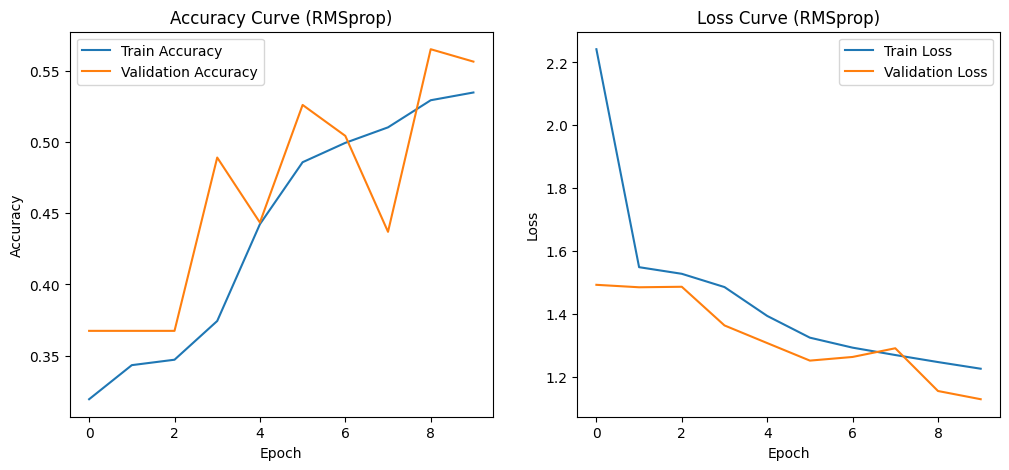

In [51]:
#GRAPHICAL REPRESENTATION OF RMSPROP OPTIMIZER
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy graph
plt.subplot(1,2,1)
plt.plot(history_rms.history['accuracy'], label='Train Accuracy')
plt.plot(history_rms.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Curve (RMSprop)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1,2,2)
plt.plot(history_rms.history['loss'], label='Train Loss')
plt.plot(history_rms.history['val_loss'], label='Validation Loss')
plt.title("Loss Curve (RMSprop)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [52]:
#CONFUSION MATRIX
import numpy as np

val_generator.reset()

predictions_rms = model_rms.predict(val_generator)

predicted_classes_rms = np.argmax(predictions_rms, axis=1)

15/15 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step


In [53]:
true_classes = val_generator.classes

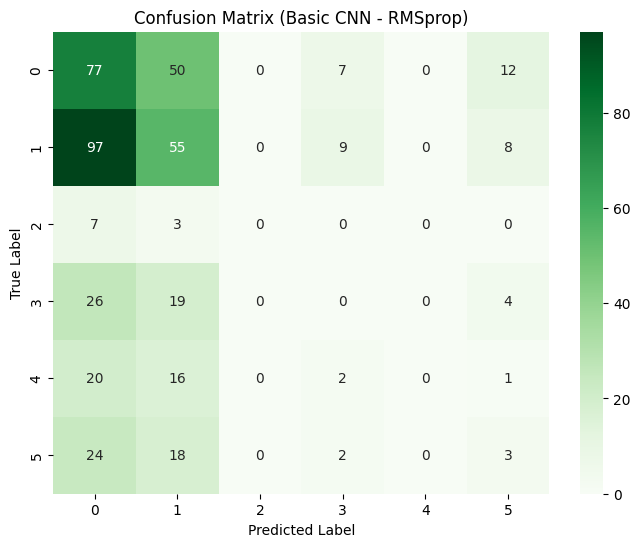

In [54]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rms = confusion_matrix(true_classes, predicted_classes_rms)

plt.figure(figsize=(8,6))
sns.heatmap(cm_rms, annot=True, fmt='d', cmap='Greens')

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Basic CNN - RMSprop)")

plt.show()

**CNN+ADAGRAD OPTIMIZER**

In [55]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model_ada = Sequential()

model_ada.add(Conv2D(32, (3,3), activation='relu', input_shape=(240,240,3)))
model_ada.add(MaxPooling2D(2,2))

model_ada.add(Conv2D(64, (3,3), activation='relu'))
model_ada.add(MaxPooling2D(2,2))

model_ada.add(Conv2D(128, (3,3), activation='relu'))
model_ada.add(MaxPooling2D(2,2))

model_ada.add(Flatten())

model_ada.add(Dense(128, activation='relu'))
model_ada.add(Dropout(0.5))

model_ada.add(Dense(6, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [56]:
#COMPILE WITH ADAGRAD
from tensorflow.keras.optimizers import Adagrad

model_ada.compile(
    optimizer=Adagrad(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [57]:
#TRAIN WITH ADAGRAD
history_ada = model_ada.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step - accuracy: 0.3910 - loss: 1.5947 - val_accuracy: 0.3174 - val_loss: 1.5155
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 171s 3s/step - accuracy: 0.3560 - loss: 1.5483 - val_accuracy: 0.3761 - val_loss: 1.4976
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 201s 3s/step - accuracy: 0.3418 - loss: 1.5254 - val_accuracy: 0.3739 - val_loss: 1.4978
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 185s 3s/step - accuracy: 0.3598 - loss: 1.5166 - val_accuracy: 0.3674 - val_loss: 1.4922
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.3900 - loss: 1.5044 - val_accuracy: 0.3630 - val_loss: 1.4939
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.3743 - loss: 1.5138 - val_accuracy: 0.4152 - val_loss: 1.4824
Epoch 7/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.3484 - loss: 1.5228 - val_accuracy: 0.4152 - val_loss: 1.4817
Epoch 8/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.4026 - loss: 1.4906 - val_accuracy: 0.4043 - v

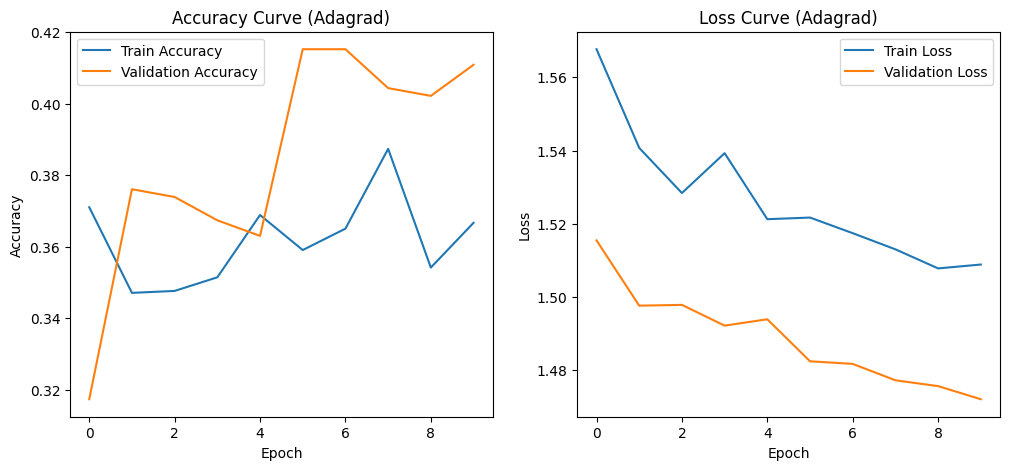

In [58]:
#GRAPH 
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy Graph
plt.subplot(1,2,1)
plt.plot(history_ada.history['accuracy'], label='Train Accuracy')
plt.plot(history_ada.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Curve (Adagrad)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss Graph
plt.subplot(1,2,2)
plt.plot(history_ada.history['loss'], label='Train Loss')
plt.plot(history_ada.history['val_loss'], label='Validation Loss')
plt.title("Loss Curve (Adagrad)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [59]:
#CONFUSION MATRIX
import numpy as np

val_generator.reset()

predictions_ada = model_ada.predict(val_generator)

predicted_classes_ada = np.argmax(predictions_ada, axis=1)

15/15 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step


In [60]:
true_classes = val_generator.classes

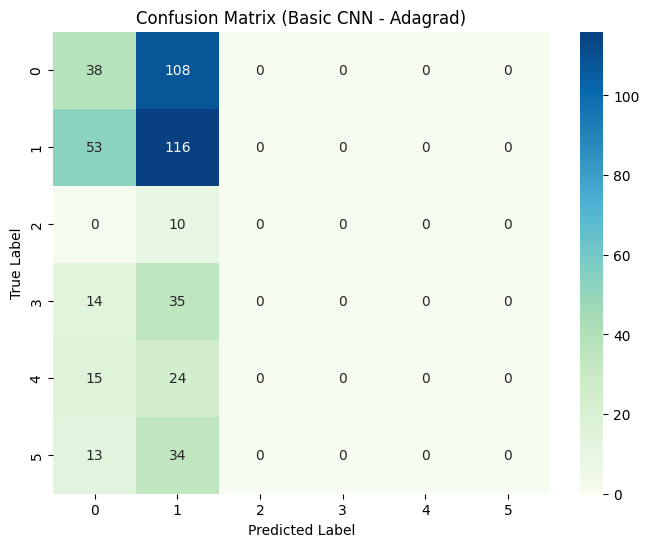

In [61]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_ada = confusion_matrix(true_classes, predicted_classes_ada)

plt.figure(figsize=(8,6))
sns.heatmap(cm_ada, annot=True, fmt='d', cmap='GnBu')

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Basic CNN - Adagrad)")

plt.show()

**VGG16 MODEL**

In [62]:
from tensorflow.keras.applications import VGG16

In [63]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(240,240,3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [64]:
#FREEZING TH BASE LAYER
for layer in base_model.layers:
    layer.trainable = False

In [65]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Flatten, Dense, Dropout

x = base_model.output
x = Flatten()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

predictions = Dense(6, activation='softmax')(x)

model_vgg = Model(inputs=base_model.input, outputs=predictions)

In [66]:
#COMPILE MODEL
from tensorflow.keras.optimizers import Adam

model_vgg.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [67]:
model_vgg.summary()

Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 240, 240, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 240, 240, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 120, 120, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 120, 120, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 120, 120, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 60, 60, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 60, 60, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 60, 60, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 60, 60, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 30, 30, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 30, 30, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 30, 30, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 30, 30, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 15, 15, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 15, 15, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 15, 15, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 15, 15, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,139,014 (80.64 MB)

 Trainable params: 6,424,326 (24.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [68]:
#TRAIN VGG16
history_vgg = model_vgg.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 829s 14s/step - accuracy: 0.3661 - loss: 1.6815 - val_accuracy: 0.5000 - val_loss: 1.3770
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 860s 15s/step - accuracy: 0.4618 - loss: 1.3804 - val_accuracy: 0.4957 - val_loss: 1.3118
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 861s 15s/step - accuracy: 0.5083 - loss: 1.2953 - val_accuracy: 0.5457 - val_loss: 1.2811
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 861s 15s/step - accuracy: 0.5407 - loss: 1.2187 - val_accuracy: 0.5283 - val_loss: 1.2489
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 824s 14s/step - accuracy: 0.5500 - loss: 1.1970 - val_accuracy: 0.5609 - val_loss: 1.2262
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 825s 14s/step - accuracy: 0.5877 - loss: 1.1177 - val_accuracy: 0.5435 - val_loss: 1.2236
Epoch 7/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 826s 14s/step - accuracy: 0.5755 - loss: 1.1126 - val_accuracy: 0.5696 - val_loss: 1.1994
Epoch 8/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 898s 15s/step - accuracy: 0.6170 - loss: 1.0439 - val_accuracy: 0.

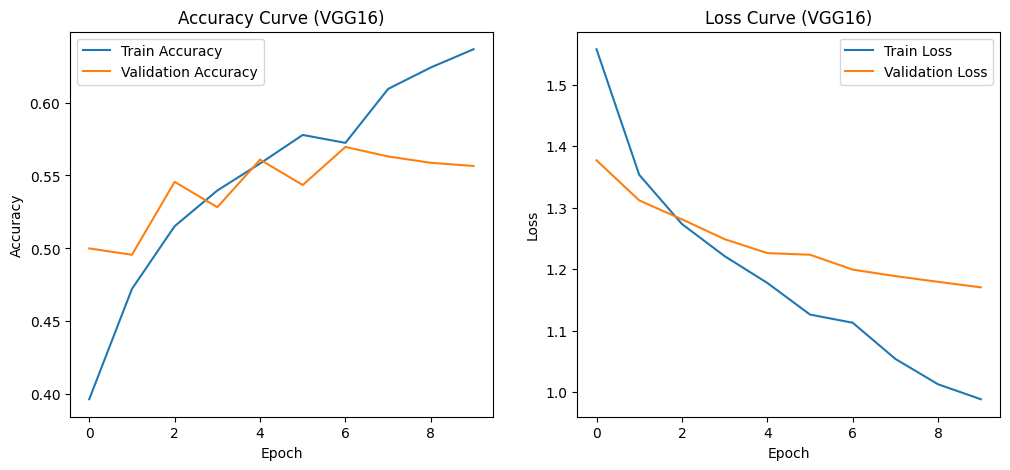

In [69]:
#GRAPHICAL REPRESANTATION
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy Graph
plt.subplot(1,2,1)
plt.plot(history_vgg.history['accuracy'], label='Train Accuracy')
plt.plot(history_vgg.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Curve (VGG16)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss Graph
plt.subplot(1,2,2)
plt.plot(history_vgg.history['loss'], label='Train Loss')
plt.plot(history_vgg.history['val_loss'], label='Validation Loss')
plt.title("Loss Curve (VGG16)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [70]:
#CONFUSION MATRIX
import numpy as np

val_generator.reset()

predictions_vgg = model_vgg.predict(val_generator)

predicted_classes_vgg = np.argmax(predictions_vgg, axis=1)

15/15 ━━━━━━━━━━━━━━━━━━━━ 165s 11s/step


In [71]:
true_classes = val_generator.classes

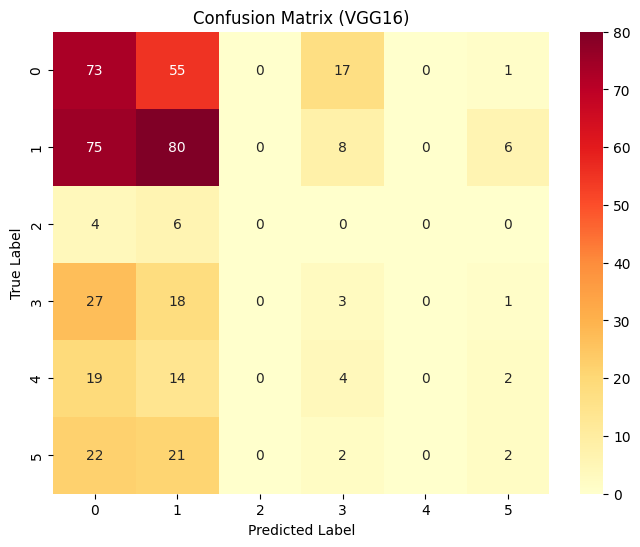

In [72]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_vgg = confusion_matrix(true_classes, predicted_classes_vgg)

plt.figure(figsize=(8,6))
sns.heatmap(cm_vgg, annot=True, fmt='d', cmap='YlOrRd')

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (VGG16)")

plt.show()

**RMSPROP OPTIMIZER**

In [73]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(240,240,3)
)

In [74]:
for layer in base_model.layers:
    layer.trainable = False

In [75]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Flatten, Dense, Dropout

x = base_model.output
x = Flatten()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

predictions = Dense(6, activation='softmax')(x)

model_vgg_rms = Model(inputs=base_model.input, outputs=predictions)

In [76]:
from tensorflow.keras.optimizers import RMSprop

model_vgg_rms.compile(
    optimizer=RMSprop(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [77]:
#TRAIN
history_vgg_rms = model_vgg_rms.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 832s 14s/step - accuracy: 0.3479 - loss: 1.6873 - val_accuracy: 0.4370 - val_loss: 1.3684
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 859s 14s/step - accuracy: 0.4591 - loss: 1.3616 - val_accuracy: 0.4870 - val_loss: 1.3344
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 863s 14s/step - accuracy: 0.5016 - loss: 1.2968 - val_accuracy: 0.5457 - val_loss: 1.2671
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 826s 14s/step - accuracy: 0.5259 - loss: 1.2671 - val_accuracy: 0.4609 - val_loss: 1.3089
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 833s 14s/step - accuracy: 0.5377 - loss: 1.2306 - val_accuracy: 0.5630 - val_loss: 1.2182
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 867s 15s/step - accuracy: 0.5536 - loss: 1.1579 - val_accuracy: 0.5478 - val_loss: 1.2282
Epoch 7/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 836s 14s/step - accuracy: 0.5668 - loss: 1.1279 - val_accuracy: 0.5696 - val_loss: 1.1943
Epoch 8/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 864s 14s/step - accuracy: 0.5876 - loss: 1.0856 - val_accuracy: 0.

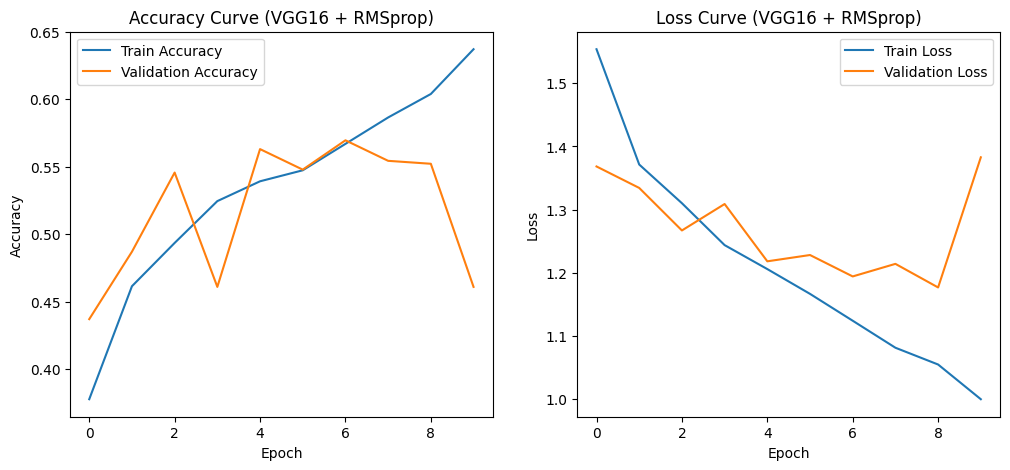

In [78]:
#GRAPH
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy Graph
plt.subplot(1,2,1)
plt.plot(history_vgg_rms.history['accuracy'], label='Train Accuracy')
plt.plot(history_vgg_rms.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Curve (VGG16 + RMSprop)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss Graph
plt.subplot(1,2,2)
plt.plot(history_vgg_rms.history['loss'], label='Train Loss')
plt.plot(history_vgg_rms.history['val_loss'], label='Validation Loss')
plt.title("Loss Curve (VGG16 + RMSprop)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [79]:
#CONFUSION MATRIX
import numpy as np

val_generator.reset()

predictions_vgg_rms = model_vgg.predict(val_generator)

predicted_classes_vgg_rms = np.argmax(predictions_vgg_rms, axis=1)

15/15 ━━━━━━━━━━━━━━━━━━━━ 168s 11s/step


In [80]:
true_classes = val_generator.classes

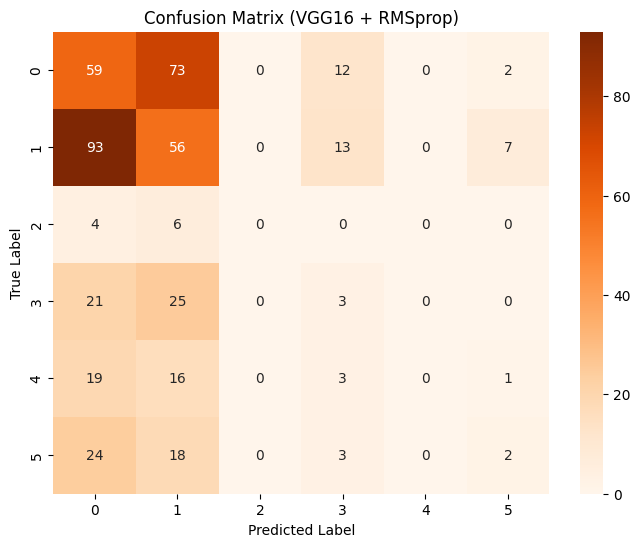

In [81]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_vgg_rms = confusion_matrix(true_classes, predicted_classes_vgg_rms)

plt.figure(figsize=(8,6))
sns.heatmap(cm_vgg_rms, annot=True, fmt='d', cmap='Oranges')

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (VGG16 + RMSprop)")

plt.show()